In [1]:
#Name = Utkarsh Yadav
#Branch/Section = CSE AIML-6
#Admission no.: 2026B15310064

import os
import shutil
import warnings
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)
warnings.filterwarnings('ignore')

required_columns = [
    'encounter_id', 'patient_id', 'admission_date', 'discharge_date',
    'age', 'age_band', 'service', 'primary_diagnosis', 'procedure',
    'admission_type', 'discharge_disposition', 'length_of_stay_days',
    'readmitted_within_30_days'
]

file_name = 'healthcare_readmission_synthetic.csv'


try:
    from google.colab import files
    print('Upload your healthcare readmission CSV file:')
    uploaded = files.upload()
    if uploaded:
        file_name = next(iter(uploaded))
except ImportError:
    print('Not running in Google Colab. Looking for:', file_name)
    if not os.path.exists(file_name):
        raise FileNotFoundError(
            'Place healthcare_readmission_synthetic.csv in the notebook folder, '
            'or open this notebook in Google Colab and upload your CSV.'
        )

raw = pd.read_csv(file_name, low_memory=False)
raw.columns = raw.columns.str.strip()

missing_required = [c for c in required_columns if c not in raw.columns]
if missing_required:
    raise ValueError(
        'Your CSV is missing required columns: ' + ', '.join(missing_required) +
        '\\nPlease upload a CSV with the same column structure as the supplied sample.'
    )

print('Loaded file:', file_name)
print('Rows (encounters):', len(raw))
print('Columns:', len(raw.columns))
display(raw.head())

Upload your healthcare readmission CSV file:


Saving healthcare_readmission_synthetic.csv to healthcare_readmission_synthetic.csv
Loaded file: healthcare_readmission_synthetic.csv
Rows (encounters): 1200
Columns: 13


,encounter_id,patient_id,admission_date,discharge_date,age,age_band,service,primary_diagnosis,procedure,admission_type,discharge_disposition,length_of_stay_days,readmitted_within_30_days
0,E000851,P00638,2024-05-05,2024-05-07,29,18-29,General Medicine,Heart failure,None recorded,Emergency,Home,2,1
1,E000731,P00474,2024-03-06,2024-03-11,33,30-44,Endocrinology,Kidney disease,Respiratory therapy,Urgent,Home,5,0
2,E000033,P00060,2025-12-09,2025-12-11,22,18-29,Cardiology,COPD,Surgical procedure,Elective,Skilled nursing facility,2,1
3,E001017,P00250,2024-11-24,2024-12-12,42,30-44,Cardiology,Type 2 diabetes,None recorded,Emergency,Home,18,0
4,E000584,P00034,2025-11-28,2025-12-05,40,30-44,Cardiology,Pneumonia,Cardiac procedure,Emergency,Other facility,7,0


In [2]:
print('Dataset shape:', raw.shape)
print('Unique encounters:', raw['encounter_id'].nunique())
print('Unique patients:', raw['patient_id'].nunique())
print('Duplicate encounter IDs:', raw['encounter_id'].duplicated().sum())
print('Readmission labels:')
display(raw['readmitted_within_30_days'].value_counts(dropna=False).to_frame('encounters'))
print('Column names:')
print(raw.columns.tolist())

Dataset shape: (1200, 13)
Unique encounters: 1200
Unique patients: 545
Duplicate encounter IDs: 0
Readmission labels:


,encounters
readmitted_within_30_days,
0,1106
1,94


Column names:
['encounter_id', 'patient_id', 'admission_date', 'discharge_date', 'age', 'age_band', 'service', 'primary_diagnosis', 'procedure', 'admission_type', 'discharge_disposition', 'length_of_stay_days', 'readmitted_within_30_days']


In [3]:
audit = raw.copy()
audit = audit.replace(r'^\\s*$', np.nan, regex=True)

missing = audit.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(audit) * 100).round(2)
missing_table = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate encounter IDs:', raw['encounter_id'].duplicated().sum())
display(missing_table)
print('Unique readmission values:', raw['readmitted_within_30_days'].dropna().unique())

Exact duplicate rows: 0
Duplicate encounter IDs: 0


,missing_count,missing_pct
procedure,32,2.67
discharge_disposition,12,1.00
primary_diagnosis,11,0.92
patient_id,0,0.00
encounter_id,0,0.00
age,0,0.00
discharge_date,0,0.00
admission_date,0,0.00
service,0,0.00
age_band,0,0.00


Unique readmission values: [1 0]


In [4]:
df = audit.copy()

for col in ['age', 'length_of_stay_days', 'readmitted_within_30_days']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

for col in ['encounter_id', 'patient_id', 'age_band', 'service',
            'primary_diagnosis', 'procedure', 'admission_type',
            'discharge_disposition']:
    df[col] = df[col].astype('string').str.strip()

df['admission_date'] = pd.to_datetime(df['admission_date'], errors='coerce')
df['discharge_date'] = pd.to_datetime(df['discharge_date'], errors='coerce')

print('Invalid/missing encounter IDs:', df['encounter_id'].isna().sum())
print('Invalid/missing patient IDs:', df['patient_id'].isna().sum())
print('Missing/non-positive length of stay:',
      (df['length_of_stay_days'].isna() | (df['length_of_stay_days'] <= 0)).sum())
print('Missing/invalid readmission flags:',
      (~df['readmitted_within_30_days'].isin([0, 1])).sum())
print('Readmission labels:', df['readmitted_within_30_days'].dropna().unique())

Invalid/missing encounter IDs: 0
Invalid/missing patient IDs: 0
Missing/non-positive length of stay: 0
Missing/invalid readmission flags: 0
Readmission labels: [1 0]


In [5]:
before_rows = len(df)
duplicate_rows = int(df.duplicated().sum())
duplicate_encounters = int(df['encounter_id'].duplicated().sum())

clean = df.drop_duplicates().copy()
clean = clean.dropna(subset=[
    'encounter_id', 'patient_id', 'length_of_stay_days',
    'readmitted_within_30_days'
])
clean = clean.drop_duplicates(subset=['encounter_id'], keep='first')
clean = clean[
    clean['length_of_stay_days'].between(1, 365)
    & clean['readmitted_within_30_days'].isin([0, 1])
].copy()

clean['readmitted_30d'] = clean['readmitted_within_30_days'].astype(bool)
clean['age_band'] = clean['age_band'].fillna('Unknown')
for col in ['service', 'primary_diagnosis', 'admission_type',
            'discharge_disposition', 'procedure']:
    clean[col] = clean[col].fillna('Unknown')

print('Rows before cleaning:', before_rows)
print('Exact duplicate rows removed:', duplicate_rows)
print('Duplicate encounter IDs observed:', duplicate_encounters)
print('Rows after cleaning:', len(clean))
print('Rows excluded:', before_rows - len(clean))
display(clean[['encounter_id', 'patient_id', 'age', 'length_of_stay_days',
               'readmitted_within_30_days']].head())

Rows before cleaning: 1200
Exact duplicate rows removed: 0
Duplicate encounter IDs observed: 0
Rows after cleaning: 1200
Rows excluded: 0


,encounter_id,patient_id,age,length_of_stay_days,readmitted_within_30_days
0,E000851,P00638,29,2,1
1,E000731,P00474,33,5,0
2,E000033,P00060,22,2,1
3,E001017,P00250,42,18,0
4,E000584,P00034,40,7,0


In [6]:
flow_summary = pd.Series({
    'encounters': len(clean),
    'unique_patients': clean['patient_id'].nunique(),
    'mean_length_of_stay_days': clean['length_of_stay_days'].mean(),
    'median_length_of_stay_days': clean['length_of_stay_days'].median(),
    'mean_encounters_per_patient': len(clean) / clean['patient_id'].nunique(),
    'readmission_within_30d_pct': clean['readmitted_30d'].mean() * 100
}).to_frame('value').round(2)

outcome_counts = clean['readmitted_30d'].map(
    {True: 'Readmitted within 30 days', False: 'Not readmitted within 30 days'}
).value_counts().rename_axis('outcome').to_frame('encounters')
outcome_counts['percent'] = (outcome_counts['encounters'] / len(clean) * 100).round(2)

display(flow_summary)
display(outcome_counts)

,value
encounters,1200.00
unique_patients,545.00
mean_length_of_stay_days,4.55
median_length_of_stay_days,4.00
mean_encounters_per_patient,2.20
readmission_within_30d_pct,7.83


,encounters,percent
outcome,,
Not readmitted within 30 days,1106,92.17
Readmitted within 30 days,94,7.83


In [7]:
los_by_outcome = clean.groupby('readmitted_30d')['length_of_stay_days'].agg(
    encounters='count', mean_los='mean', median_los='median',
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
).round(2)

encounters_per_patient = clean.groupby('patient_id').size().rename('encounters')
frequency_summary = encounters_per_patient.value_counts().sort_index().rename_axis(
    'encounters_per_patient'
).to_frame('number_of_patients')

display(los_by_outcome)
display(frequency_summary.head(15))

,encounters,mean_los,median_los,q1,q3
readmitted_30d,,,,,
False,1106,4.56,4.0,2.0,6.0
True,94,4.53,4.0,2.0,7.0


,number_of_patients
encounters_per_patient,
1,185
2,176
3,110
4,43
5,25
6,6


In [8]:
clean['los_band'] = pd.cut(
    clean['length_of_stay_days'],
    bins=[0, 2, 5, 10, 365],
    labels=['1-2 days', '3-5 days', '6-10 days', '11+ days']
)

def group_readmission(data, column, min_n=20):
    result = data.groupby(column, dropna=False, observed=False).agg(
        encounters=('encounter_id', 'count'),
        readmissions_within_30d=('readmitted_30d', 'sum'),
        readmission_pct=('readmitted_30d', 'mean')
    ).reset_index()
    result['readmission_pct'] = (result['readmission_pct'] * 100).round(2)
    result['small_group'] = result['encounters'] < min_n
    return result.sort_values('encounters', ascending=False)

age_readmission = group_readmission(clean, 'age_band')
los_readmission = group_readmission(clean, 'los_band')
service_readmission = group_readmission(clean, 'service')
diagnosis_readmission = group_readmission(clean, 'primary_diagnosis')
admission_type_readmission = group_readmission(clean, 'admission_type')
disposition_readmission = group_readmission(clean, 'discharge_disposition')

display(age_readmission)
display(los_readmission)
display(service_readmission)
display(diagnosis_readmission)
display(admission_type_readmission)
display(disposition_readmission)

,age_band,encounters,readmissions_within_30d,readmission_pct,small_group
4,75+,276,20,7.25,False
2,45-59,262,21,8.02,False
1,30-44,242,15,6.20,False
3,60-74,224,21,9.38,False
0,18-29,196,17,8.67,False


,los_band,encounters,readmissions_within_30d,readmission_pct,small_group
1,3-5 days,479,30,6.26,False
0,1-2 days,345,30,8.70,False
2,6-10 days,322,31,9.63,False
3,11+ days,54,3,5.56,False


,service,encounters,readmissions_within_30d,readmission_pct,small_group
2,General Medicine,406,33,8.13,False
0,Cardiology,226,19,8.41,False
1,Endocrinology,216,19,8.80,False
3,Respiratory,206,14,6.80,False
4,Surgery,146,9,6.16,False


,primary_diagnosis,encounters,readmissions_within_30d,readmission_pct,small_group
5,Type 2 diabetes,342,26,7.60,False
1,Heart failure,199,21,10.55,False
4,Pneumonia,194,11,5.67,False
0,COPD,162,13,8.02,False
2,Hypertension,150,11,7.33,False
3,Kidney disease,142,9,6.34,False
6,Unknown,11,3,27.27,True


,admission_type,encounters,readmissions_within_30d,readmission_pct,small_group
1,Emergency,671,53,7.90,False
0,Elective,298,25,8.39,False
2,Urgent,231,16,6.93,False


,discharge_disposition,encounters,readmissions_within_30d,readmission_pct,small_group
0,Home,867,67,7.73,False
2,Rehabilitation,136,10,7.35,False
3,Skilled nursing facility,119,14,11.76,False
1,Other facility,66,3,4.55,False
4,Unknown,12,0,0.00,True


In [9]:
categorical_cols = ['service', 'primary_diagnosis', 'admission_type',
                    'discharge_disposition', 'procedure']
category_summary = {}
for col in categorical_cols:
    category_summary[col] = clean.groupby(col)['readmitted_30d'].agg(
        encounters='count', readmission_rate='mean'
    )
    category_summary[col]['readmission_rate'] *= 100
    category_summary[col] = category_summary[col].round(2)

for col, summary in category_summary.items():
    print('Readmission summary by', col)
    display(summary.sort_values('encounters', ascending=False))

Readmission summary by service


,encounters,readmission_rate
service,,
General Medicine,406,8.13
Cardiology,226,8.41
Endocrinology,216,8.80
Respiratory,206,6.80
Surgery,146,6.16


Readmission summary by primary_diagnosis


,encounters,readmission_rate
primary_diagnosis,,
Type 2 diabetes,342,7.60
Heart failure,199,10.55
Pneumonia,194,5.67
COPD,162,8.02
Hypertension,150,7.33
Kidney disease,142,6.34
Unknown,11,27.27


Readmission summary by admission_type


,encounters,readmission_rate
admission_type,,
Emergency,671,7.90
Elective,298,8.39
Urgent,231,6.93


Readmission summary by discharge_disposition


,encounters,readmission_rate
discharge_disposition,,
Home,867,7.73
Rehabilitation,136,7.35
Skilled nursing facility,119,11.76
Other facility,66,4.55
Unknown,12,0.00


Readmission summary by procedure


,encounters,readmission_rate
procedure,,
Blood test,372,8.33
None recorded,311,9.32
Imaging,207,7.25
Respiratory therapy,111,7.21
Surgical procedure,86,6.98
Cardiac procedure,81,3.70
Unknown,32,6.25


In [10]:
missing_clean = clean.isna().sum().sort_values(ascending=False)
missing_clean_pct = (missing_clean / len(clean) * 100).round(2)
missing_clean_table = pd.DataFrame({
    'missing_count': missing_clean,
    'missing_pct': missing_clean_pct
})
display(missing_clean_table)

service_readmission = group_readmission(clean, 'service', min_n=20)
diagnosis_readmission = group_readmission(clean, 'primary_diagnosis', min_n=20)
display(service_readmission)
display(diagnosis_readmission)

,missing_count,missing_pct
encounter_id,0,0.0
patient_id,0,0.0
admission_date,0,0.0
discharge_date,0,0.0
age,0,0.0
age_band,0,0.0
service,0,0.0
primary_diagnosis,0,0.0
procedure,0,0.0
admission_type,0,0.0


,service,encounters,readmissions_within_30d,readmission_pct,small_group
2,General Medicine,406,33,8.13,False
0,Cardiology,226,19,8.41,False
1,Endocrinology,216,19,8.80,False
3,Respiratory,206,14,6.80,False
4,Surgery,146,9,6.16,False


,primary_diagnosis,encounters,readmissions_within_30d,readmission_pct,small_group
5,Type 2 diabetes,342,26,7.60,False
1,Heart failure,199,21,10.55,False
4,Pneumonia,194,11,5.67,False
0,COPD,162,13,8.02,False
2,Hypertension,150,11,7.33,False
3,Kidney disease,142,9,6.34,False
6,Unknown,11,3,27.27,True


In [11]:
los_99 = clean['length_of_stay_days'].quantile(0.99)
cases = {
    'All cleaned encounters': clean,
    'Length of stay at least 2 days': clean[clean['length_of_stay_days'] >= 2],
    'Exclude length of stay above 99th percentile': clean[
        clean['length_of_stay_days'] <= los_99
    ],
    'Known age and service only': clean[
        clean['age'].notna() & clean['service'].ne('Unknown')
    ]
}

sensitivity_rows = []
for name, subset in cases.items():
    sensitivity_rows.append({
        'scenario': name,
        'encounters': len(subset),
        'patients': subset['patient_id'].nunique(),
        'readmission_within_30d_pct': subset['readmitted_30d'].mean() * 100,
        'mean_los_days': subset['length_of_stay_days'].mean()
    })

sensitivity = pd.DataFrame(sensitivity_rows).round(2)
display(sensitivity)
print('99th percentile length-of-stay cutoff:', round(los_99, 2), 'days')

,scenario,encounters,patients,readmission_within_30d_pct,mean_los_days
0,All cleaned encounters,1200,545,7.83,4.55
1,Length of stay at least 2 days,1033,524,8.13,5.13
2,Exclude length of stay above 99th percentile,1191,543,7.89,4.45
3,Known age and service only,1200,545,7.83,4.55


99th percentile length-of-stay cutoff: 14.0 days


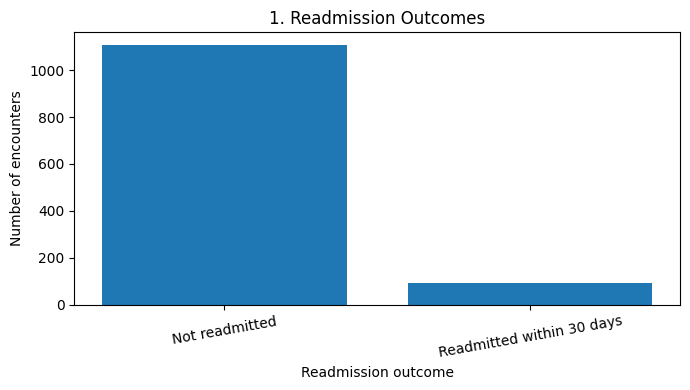

In [12]:
outcome_plot = clean['readmitted_30d'].map({
    False: 'Not readmitted', True: 'Readmitted within 30 days'
}).value_counts().reindex(['Not readmitted', 'Readmitted within 30 days'])
plt.figure(figsize=(7, 4))
plt.bar(outcome_plot.index, outcome_plot.values)
plt.title('1. Readmission Outcomes')
plt.xlabel('Readmission outcome')
plt.ylabel('Number of encounters')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('01_readmission_outcomes.png', dpi=150)
plt.show()

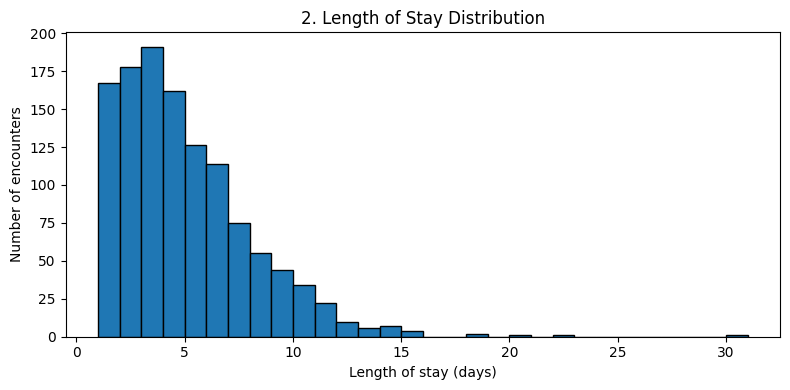

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(clean['length_of_stay_days'], bins=range(
    1, int(clean['length_of_stay_days'].max()) + 2
), edgecolor='black')
plt.title('2. Length of Stay Distribution')
plt.xlabel('Length of stay (days)')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.savefig('02_length_of_stay.png', dpi=150)
plt.show()

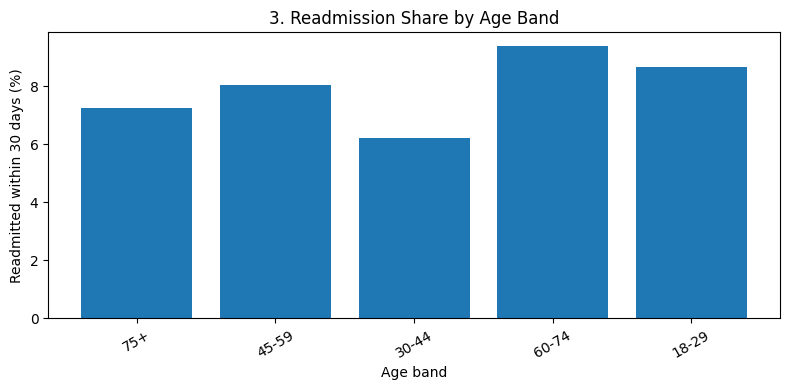

In [14]:
age_chart = age_readmission[~age_readmission['small_group']].copy()
plt.figure(figsize=(8, 4))
plt.bar(age_chart['age_band'].astype(str), age_chart['readmission_pct'])
plt.title('3. Readmission Share by Age Band')
plt.xlabel('Age band')
plt.ylabel('Readmitted within 30 days (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('03_readmission_by_age.png', dpi=150)
plt.show()

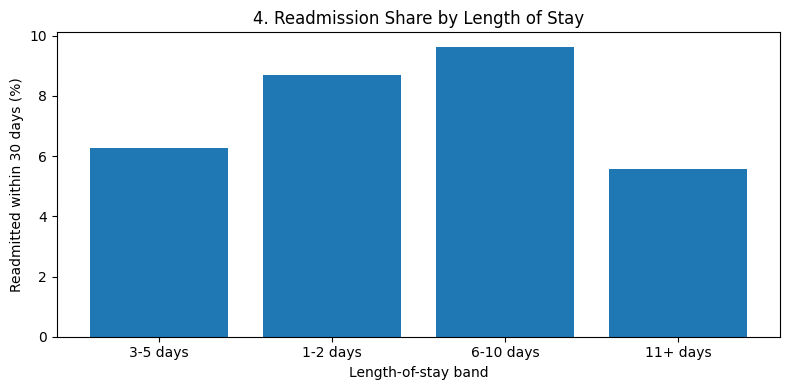

In [15]:
los_chart = los_readmission.dropna(subset=['los_band'])
plt.figure(figsize=(8, 4))
plt.bar(los_chart['los_band'].astype(str), los_chart['readmission_pct'])
plt.title('4. Readmission Share by Length of Stay')
plt.xlabel('Length-of-stay band')
plt.ylabel('Readmitted within 30 days (%)')
plt.tight_layout()
plt.savefig('04_readmission_by_los.png', dpi=150)
plt.show()

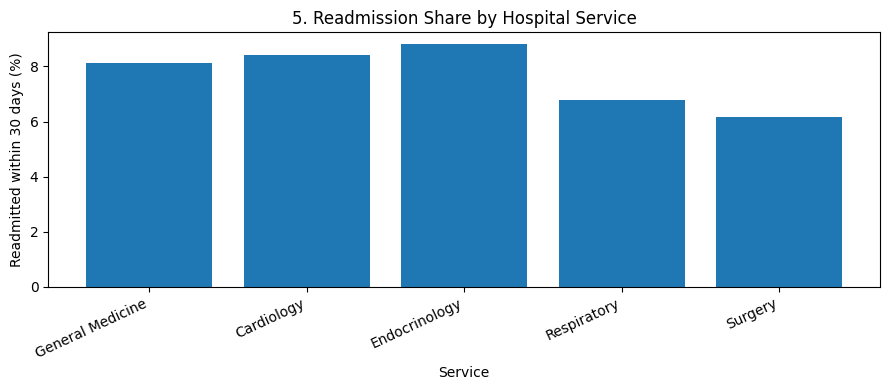

In [16]:
service_chart = service_readmission[~service_readmission['small_group']]
plt.figure(figsize=(9, 4))
plt.bar(service_chart['service'].astype(str), service_chart['readmission_pct'])
plt.title('5. Readmission Share by Hospital Service')
plt.xlabel('Service')
plt.ylabel('Readmitted within 30 days (%)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('05_readmission_by_service.png', dpi=150)
plt.show()

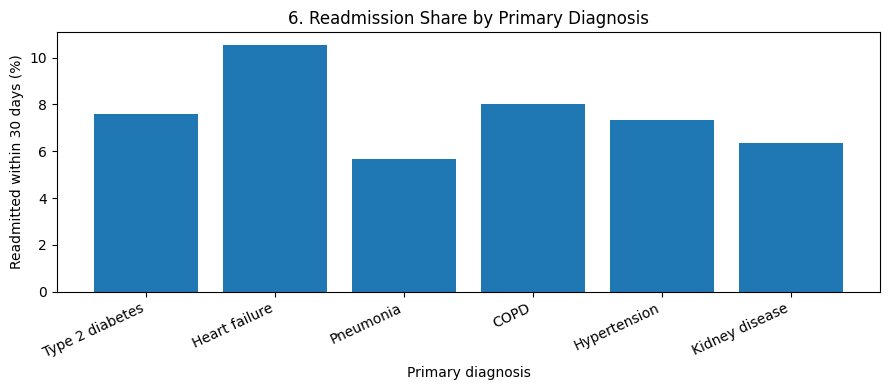

In [17]:
diagnosis_chart = diagnosis_readmission[~diagnosis_readmission['small_group']]
plt.figure(figsize=(9, 4))
plt.bar(diagnosis_chart['primary_diagnosis'].astype(str),
        diagnosis_chart['readmission_pct'])
plt.title('6. Readmission Share by Primary Diagnosis')
plt.xlabel('Primary diagnosis')
plt.ylabel('Readmitted within 30 days (%)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('06_readmission_by_diagnosis.png', dpi=150)
plt.show()

In [18]:
overall_readmit = clean['readmitted_30d'].mean() * 100
mean_los = clean['length_of_stay_days'].mean()
median_los = clean['length_of_stay_days'].median()
top_age = age_readmission.loc[~age_readmission['small_group']].sort_values(
    'readmission_pct', ascending=False
).head(1)
top_service = service_readmission.loc[~service_readmission['small_group']].sort_values(
    'readmission_pct', ascending=False
).head(1)

top_age_text = (
    f"{top_age.iloc[0]['age_band']}: {top_age.iloc[0]['readmission_pct']:.1f}%"
    if len(top_age) else 'Not enough group data'
)
top_service_text = (
    f"{top_service.iloc[0]['service']}: {top_service.iloc[0]['readmission_pct']:.1f}%"
    if len(top_service) else 'Not enough group data'
)

report = f'''PROJECT 07 - HEALTHCARE READMISSION & PATIENT FLOW
Data source: Uploaded healthcare readmission CSV ({file_name})

SUMMARY
Cleaned encounters: {len(clean):,}
Unique de-identified patients: {clean['patient_id'].nunique():,}
Mean encounters per patient: {len(clean) / clean['patient_id'].nunique():.2f}
Mean length of stay: {mean_los:.2f} days
Median length of stay: {median_los:.2f} days
Readmitted within 30 days: {overall_readmit:.2f}%

GROUP PATTERNS
Highest readmission percentage among sufficiently large age groups: {top_age_text}
Highest readmission percentage among sufficiently large services: {top_service_text}

DATA QUALITY
Exact duplicate rows in source: {duplicate_rows:,}
Duplicate encounter IDs observed: {duplicate_encounters:,}
Rows retained after cleaning: {len(clean):,}
Rows excluded by cleaning: {before_rows - len(clean):,}

OPERATIONAL REVIEW IDEAS
1. Review patient-flow processes for groups with longer recorded stays, without assuming that length of stay causes readmission.
2. Examine discharge planning and follow-up workflows as potential areas for a separate quality-improvement study.
3. Check missing values and category consistency before comparing services or diagnosis groups.
4. Validate apparent group differences on a more recent, representative dataset.

LIMITATIONS & DISCLAIMER
This is a retrospective descriptive analysis of synthetic/de-identified data. It does not establish causality, predict an individual's outcome, or provide clinical advice. The supplied 30-day readmission flag is used as provided; exact time-to-readmission is not reconstructed. Group differences may reflect data quality, access, coding, case mix or other unmeasured factors. No patient-level risk score or clinical decision tool is created.
'''
print(report)

PROJECT 07 - HEALTHCARE READMISSION & PATIENT FLOW
Data source: Uploaded healthcare readmission CSV (healthcare_readmission_synthetic.csv)

SUMMARY
Cleaned encounters: 1,200
Unique de-identified patients: 545
Mean encounters per patient: 2.20
Mean length of stay: 4.55 days
Median length of stay: 4.00 days
Readmitted within 30 days: 7.83%

GROUP PATTERNS
Highest readmission percentage among sufficiently large age groups: 60-74: 9.4%
Highest readmission percentage among sufficiently large services: Endocrinology: 8.8%

DATA QUALITY
Exact duplicate rows in source: 0
Duplicate encounter IDs observed: 0
Rows retained after cleaning: 1,200
Rows excluded by cleaning: 0

OPERATIONAL REVIEW IDEAS
1. Review patient-flow processes for groups with longer recorded stays, without assuming that length of stay causes readmission.
2. Examine discharge planning and follow-up workflows as potential areas for a separate quality-improvement study.
3. Check missing values and category consistency before com

In [19]:
folder = 'project07_results'
os.makedirs(folder, exist_ok=True)

clean.to_csv(f'{folder}/clean_encounters.csv', index=False)
missing_table.to_csv(f'{folder}/source_missingness_audit.csv')
missing_clean_table.to_csv(f'{folder}/clean_missingness_audit.csv')
flow_summary.to_csv(f'{folder}/patient_flow_summary.csv')
outcome_counts.to_csv(f'{folder}/readmission_outcomes.csv')
los_by_outcome.to_csv(f'{folder}/length_of_stay_by_outcome.csv')
frequency_summary.to_csv(f'{folder}/encounter_frequency_per_patient.csv')
age_readmission.to_csv(f'{folder}/readmission_by_age.csv', index=False)
los_readmission.to_csv(f'{folder}/readmission_by_length_of_stay.csv', index=False)
service_readmission.to_csv(f'{folder}/readmission_by_service.csv', index=False)
diagnosis_readmission.to_csv(f'{folder}/readmission_by_diagnosis.csv', index=False)
admission_type_readmission.to_csv(f'{folder}/readmission_by_admission_type.csv', index=False)
disposition_readmission.to_csv(f'{folder}/readmission_by_discharge_disposition.csv', index=False)
sensitivity.to_csv(f'{folder}/sensitivity_analysis.csv', index=False)

with open(f'{folder}/conclusions_and_limitations.txt', 'w', encoding='utf-8') as f:
    f.write(report)

chart_files = [
    '01_readmission_outcomes.png', '02_length_of_stay.png',
    '03_readmission_by_age.png', '04_readmission_by_los.png',
    '05_readmission_by_service.png', '06_readmission_by_diagnosis.png'
]
for image_file in chart_files:
    if os.path.exists(image_file):
        shutil.copy(image_file, folder)

shutil.make_archive(folder, 'zip', folder)
print('Created:', folder + '.zip')
print('In Google Colab, open the Files panel to download the ZIP.')

Created: project07_results.zip
In Google Colab, open the Files panel to download the ZIP.
